<h1 style="color:#003366;">NOVA IMS | MSc in Information Management</h1>
<h2 style="color:#006699;">Data Mining 2025/2026</h2>

<hr style="border:1px solid #006699;">

<h3><b>Group Project:</b> “Why are they not here today?”</h3>
<p><b>Notebook:</b> <i>Clustering</i></p>

<h3>Group 16</h3>
<ul>
  <li><b>Beatriz Correia</b> – 20250895</li>
  <li><b>Filipa Brito</b> – 202211807</li>
  <li><b>Rita Silva</b> – 20221920</li>
  <li><b>Rodrigo Conceição.</b> – 20220562</li>
</ul>

#### <font color='#006699'>Table of Contents </font> <a class="anchor" id='toc'></a> 
- [0. Imports](#p0)
- [1. Data Loading](#p1)
- [2. Feature Engineering](#p2)
  - [2.1 Encoding the Reason for Absence (Frequency Encoding)](#p2-1)
  - [2.2 Cyclical Encoding of Months and Weekdays](#p2-2)
- [3. Feature Selection](#p3)
- [4. Scaling](#p4)
- [5. K-Means Clustering (Exploratory)](#p5)
  - [5.1 Determine the Optimal K](#p5-1)
  - [5.2 Final K-Means Model (k = 6)](#p5-2)
- [6. K-Prototypes Clustering Analysis](#p6)
  - [6.1 Determine the Optimal K](#p6-1)
  - [6.2 Fitting Final K-Prototypes Models (k = 7–9)](#p6-2)
- [7. Hierarchical Clustering (Ward)](#p7)
- [8. Self-Organizing Maps (SOM)](#p8)
- [9. Final Model Selection and Export](#p9)
 
 

<font color='#006699' size=6>0. Imports</font> <a class="anchor" id="p0"></a>
  
[Back to TOC](#toc)

In [350]:
# pip install minisom
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import gower
import umap
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score
from minisom import MiniSom
from sklearn.preprocessing import StandardScaler, OneHotEncoder, MinMaxScaler
from umap import UMAP
from kmodes.kprototypes import KPrototypes
from sklearn.decomposition import PCA
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

<font color='#006699' size=6>1. Data Loading</font> <a class="anchor" id="p1"></a>
  
[Back to TOC](#toc)

In [351]:
absent_for_clustering = pd.read_csv("absent_preprocessed.csv")
absent_for_clustering.head()

,ID,Reason for absence,Month of absence,Day of the week,Transportation expense,Estimated commute time,Service time,Years until retirement,Disciplinary failure,Education,Number of children,Social drinker,Social smoker,Number of pets,Body mass index,Absenteeism time in hours,Age
0,11,Unjustified absence,July,Tuesday,289.0,69.0,13.0,32.0,0,1,2.0,1,0,1.0,30.0,4.0,33.0
1,36,Unspecified,July,Tuesday,118.0,26.0,18.0,15.0,1,1,1.0,1,0,0.0,31.0,8.0,50.0
2,3,Medical consultation,July,Wednesday,179.0,108.0,18.0,27.0,0,1,0.0,1,0,0.0,31.0,2.0,38.0
3,7,Diseases of the eye and adnexa,July,Thursday,279.0,5.0,14.0,26.0,0,1,2.0,1,1,0.0,24.0,4.0,39.0
4,11,Medical consultation,July,Thursday,289.0,69.0,13.0,32.0,0,1,2.0,1,0,1.0,30.0,2.0,33.0


In [352]:
# Create a copy of the dataset to be used for interpretation (keeps original text)
absent_interpret = absent_for_clustering.copy()


<font color='#006699' size=6>2. Feature Engineering</font> <a class="anchor" id="p2"></a>
  
[Back to TOC](#toc)

<h4><b>2.1 Encoding the Reason for Absence (Frequency Encoding)</b></h4>

In [353]:
# Calculate table of frequency
reason_freq_table = (
    absent_for_clustering['Reason for absence']
        .value_counts(normalize=True)
        .reset_index()
)

reason_freq_table.columns = ['Reason for absence', 'frequency']

In [354]:
# Frequency encoding
reason_freq = absent_for_clustering['Reason for absence'].value_counts(normalize=True)
absent_for_clustering['reason_freq'] = absent_for_clustering['Reason for absence'].map(reason_freq)


In [355]:
absent_for_clustering = absent_for_clustering.drop(columns=['Reason for absence'])


The variable "Reason for absence" is categorical with many distinct values. One-hot encoding would significantly increase dimensionality and sparsity.<br>
<br>
Instead, we apply **frequency enconding**, which:
- preserves information about how common each reason is
- produces a single numerical feature

<h4><b>2.2 Cyclical Encoding of Months and Weekdays</b></h4>

In [356]:
# Mapping the months to numbers
month_map = {
    'January': 1, 'February': 2, 'March': 3, 'April': 4,
    'May': 5, 'June': 6, 'July': 7, 'August': 8,
    'September': 9, 'October': 10, 'November': 11, 'December': 12
}

# Save reference table for future interpretation.
month_table = (
    pd.DataFrame(list(month_map.items()), columns=['Month of absence', 'Month_num'])
)


In [357]:
# Mapping the days to numbers
day_map = {
    'Monday': 1, 'Tuesday': 2, 'Wednesday': 3,
    'Thursday': 4, 'Friday': 5
}

day_table = (
    pd.DataFrame(list(day_map.items()), columns=['Day of the week', 'Day_num'])
)


In [358]:
absent_for_clustering['Month_num'] = (
    absent_for_clustering['Month of absence']
    .astype(str).str.strip()
    .map(month_map)
)

absent_for_clustering['Day_num'] = (
    absent_for_clustering['Day of the week']
    .astype(str).str.strip()
    .map(day_map)
)

In [359]:
absent_for_clustering['month_sin'] = np.sin(2 * np.pi * absent_for_clustering['Month_num'] / 12)
absent_for_clustering['month_cos'] = np.cos(2 * np.pi * absent_for_clustering['Month_num'] / 12)


In [360]:
absent_for_clustering['day_sin'] = np.sin(2 * np.pi * absent_for_clustering['Day_num'] / 5)
absent_for_clustering['day_cos'] = np.cos(2 * np.pi * absent_for_clustering['Day_num'] / 5)


In [361]:
absent_for_clustering = absent_for_clustering.drop(columns=['Month_num', 'Day_num', 'Month of absence', 'Day of the week'])


In this section, we created a cyclical calendar for the onths of the year and days of the week.<br>
<br>
To preserve this circular structure, we applied **sine and consine transformation**:
- month of absence - sin/cos (period = 12)
- day of the week - sin/cos (period = 5)

<font color='#006699' size=6>3. Feature Selection</font> <a class="anchor" id="p3"></a>
  
[Back to TOC](#toc)

Before clustering, we will analyze feature variability and correlations to remove redundant, low-information, or non-actionable variables

In [362]:
absent_for_clustering.nunique().sort_values()

Social smoker                 2
Social drinker                2
Disciplinary failure          2
Number of pets                4
Education                     4
day_sin                       5
Number of children            5
day_cos                       5
Absenteeism time in hours    11
month_sin                    11
month_cos                    11
Body mass index              17
Service time                 18
reason_freq                  21
Age                          22
Years until retirement       22
Transportation expense       23
Estimated commute time       29
ID                           36
dtype: int64

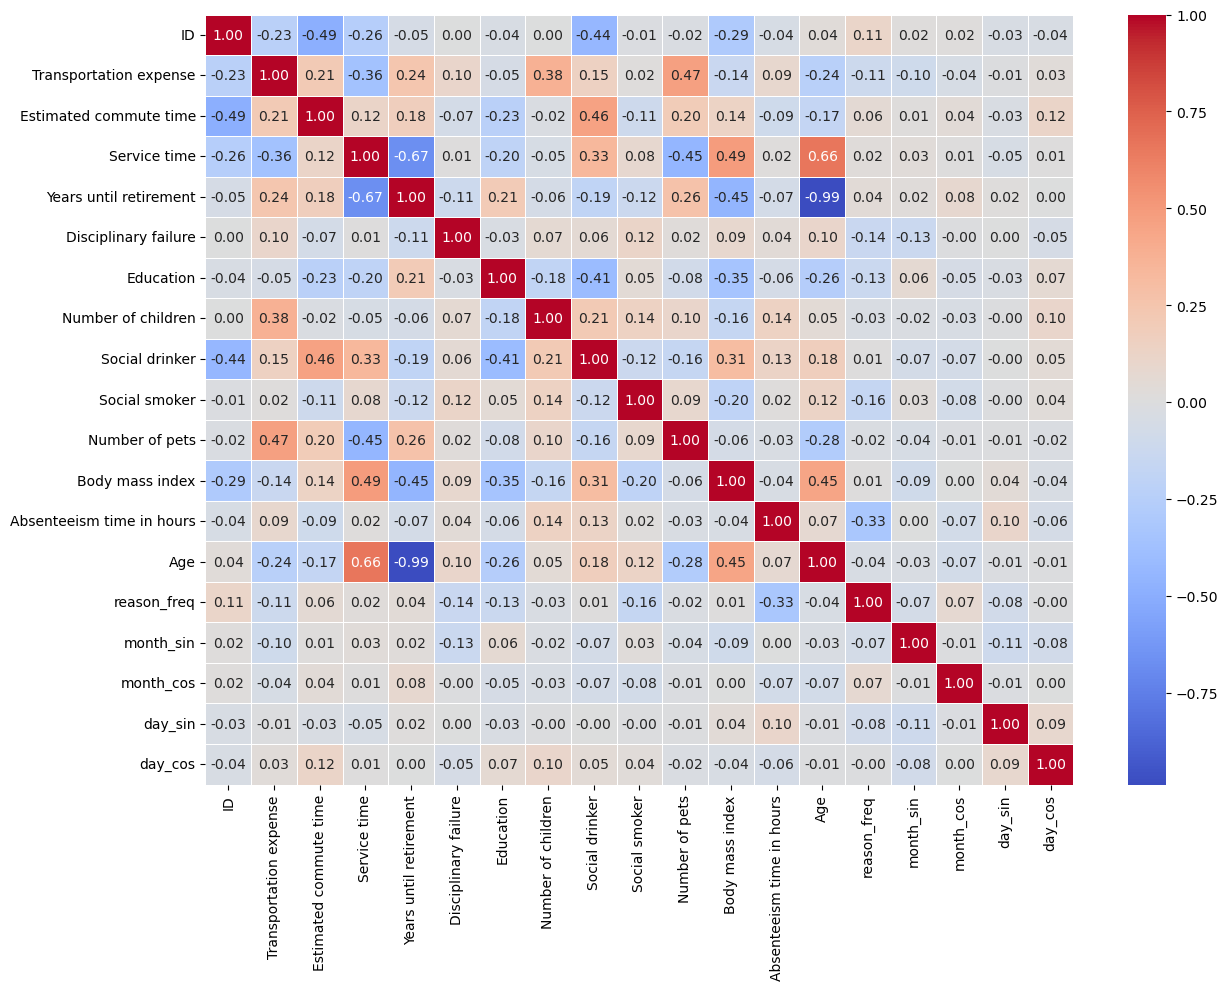

In [363]:
plt.figure(figsize=(14, 10))
sns.heatmap(
    absent_for_clustering.corr(),
    cmap="coolwarm",
    annot=True,          
    fmt=".2f",           
    linewidths=0.5
)
plt.show()

In [364]:
# Years until retirement is strongly correlated with Age and Service time and does not add independent information for clustering
absent_for_clustering = absent_for_clustering.drop(columns=['Years until retirement'])

In [365]:
for col in absent_for_clustering.columns:
    print(f"\n\n==================== {col} ====================")
    print(absent_for_clustering[col].value_counts())




==================== ID ====================
3     114
28     79
34     55
20     48
22     44
11     42
15     38
36     36
14     32
24     31
33     26
10     26
1      24
17     22
5      19
13     17
18     17
25     11
9      10
12      8
6       8
27      7
30      7
23      7
2       6
7       6
26      5
32      5
29      5
19      3
21      3
31      3
8       2
16      2
4       1
35      1
Name: ID, dtype: int64


==================== Transportation expense ====================
179.0    181
118.0     94
225.0     84
235.0     60
260.0     48
289.0     47
291.0     41
155.0     32
246.0     31
361.0     26
248.0     26
369.0     17
330.0     17
378.0     10
228.0     10
189.0      8
233.0      8
157.0      7
184.0      7
279.0      6
300.0      5
268.0      3
231.0      2
Name: Transportation expense, dtype: int64


==================== Estimated commute time ====================
108.0    114
50.0      84
54.0      82
22.0      58
94.0      53
28.0      49
69.0      42
26.

In [366]:
absent_for_clustering = absent_for_clustering.drop(columns=['Body mass index', 'Social smoker', 'Education', 'Disciplinary failure', 'ID'])

The following criteria guided feature removal:
- Identifiers with no analytical meaning (for example: ID)
- Highly aggregated variable derived from the same base measures
- Variables with very low variance or strong redundancy

Remove variables that are either identifiers, redundant, or weakly informative
- ID: unique identifier with no analytical meaning
- Body mass index: derived from height and weight, adds redundant information
- Social smoker: highly sparse and weakly related to absence patterns
- Education: categorical with limited variance and low clustering contribution
- Disciplinary failure: very rare event, introduces noise rather than structure


<font color='#006699' size=6>4. Scaling</font> <a class="anchor" id="p4"></a>
  
[Back to TOC](#toc)

In [367]:
absent_for_clustering.dtypes


Transportation expense       float64
Estimated commute time       float64
Service time                 float64
Number of children           float64
Social drinker                 int64
Number of pets               float64
Absenteeism time in hours    float64
Age                          float64
reason_freq                  float64
month_sin                    float64
month_cos                    float64
day_sin                      float64
day_cos                      float64
dtype: object

In [368]:
scaler = StandardScaler()

absent_scaled = absent_for_clustering.copy()

absent_scaled = scaler.fit_transform(
    absent_scaled
)


Clustering algorithms based on distance are sensitive to feature scale. Therefore, numerical variables are standardized using **StandardScaler**.

<font color='#006699' size=6>5. K-Means Clustering</font> <a class="anchor" id="p5"></a>
  
[Back to TOC](#toc)

<h4><b>5.1 Determine the optimal K</b></h4>

c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

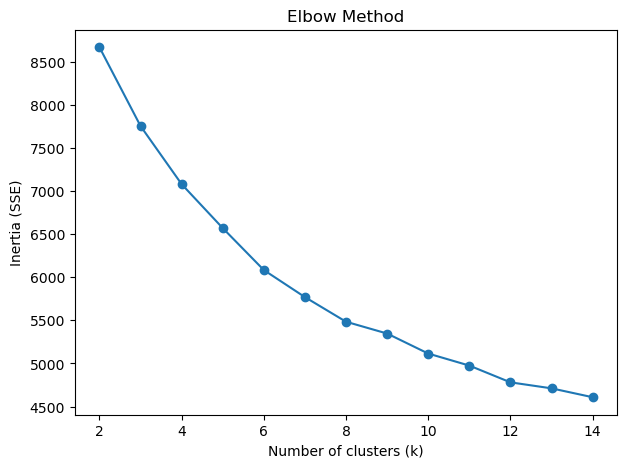

In [369]:
ks = range(2, 15)
inertias = []

for k in ks:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(absent_scaled)
    inertias.append(kmeans.inertia_)

plt.figure(figsize=(7,5))
plt.plot(ks, inertias, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia (SSE)")
plt.title("Elbow Method")
plt.show()


The elbow around k = 6 suggests that increasing the number of clusters beyond this point does not significantly improve compactness. This indicates that 6 clusters provide a good trade-off between model simplicity and explanatory power.

c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


k = 2 → Silhouette = 0.1418
k = 3 → Silhouette = 0.1502
k = 4 → Silhouette = 0.1732


c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


k = 5 → Silhouette = 0.1773
k = 6 → Silhouette = 0.1856
k = 7 → Silhouette = 0.1724
k = 8 → Silhouette = 0.1757


c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


k = 9 → Silhouette = 0.1732
k = 10 → Silhouette = 0.1683
k = 11 → Silhouette = 0.1708


c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


k = 12 → Silhouette = 0.1709
k = 13 → Silhouette = 0.1794


c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


k = 14 → Silhouette = 0.1676


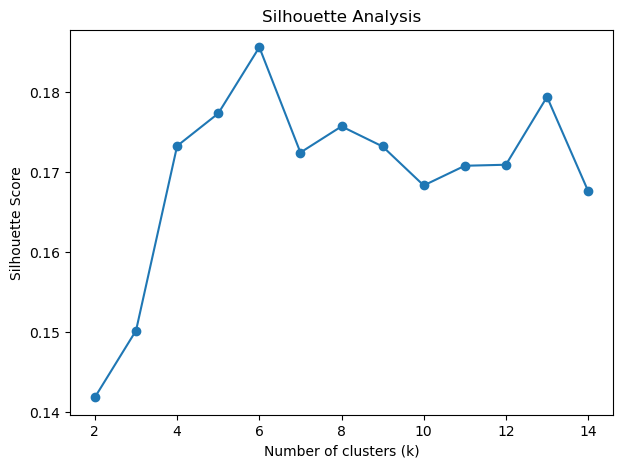

In [370]:
silhouette_scores = []

for k in range(2, 15):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(absent_scaled)
    score = silhouette_score(absent_scaled, labels)
    silhouette_scores.append(score)
    print(f"k = {k} → Silhouette = {score:.4f}")


plt.figure(figsize=(7,5))
plt.plot(range(2, 15), silhouette_scores, marker='o')
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.show()


The silhouette analysis supports the elbow method, indicating that k = 6 yields a reasonable balance between cohesion and separation, without over-fragmenting the data.

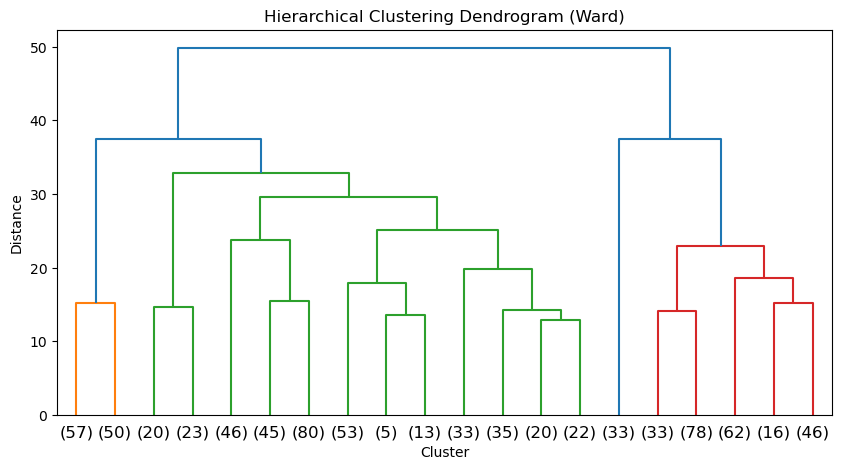

In [371]:
hclustering = linkage(absent_scaled, 'ward')

plt.figure(figsize=(10,5))
dendrogram(hclustering, truncate_mode='lastp', p=20)
plt.title("Hierarchical Clustering Dendrogram (Ward)")
plt.xlabel("Cluster")
plt.ylabel("Distance")
plt.show()


The dendrogram corroborates the findings from both the inertia and silhouette metrics, indicating that a segmentation into approximately six clusters is most natural. Although alternative solutions with two or four clusters are also visible, the combined evidence from all evaluation metrics supports proceeding with a six-cluster solution.

<h4><b>5.2 Final K-Means Model (k = 6)</b></h4>

In [372]:
kmeans = KMeans(
    n_clusters=6,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(absent_scaled)

c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


In [373]:
df_clusters = absent_for_clustering.copy()
df_clusters['cluster'] = cluster_labels


In [374]:
df_clusters['cluster'].value_counts().sort_index()


0    133
1    174
2     44
3    235
4    143
5     41
Name: cluster, dtype: int64

In [375]:
cluster_profile = df_clusters.groupby('cluster').mean()
cluster_profile

,Transportation expense,Estimated commute time,Service time,Number of children,Social drinker,Number of pets,Absenteeism time in hours,Age,reason_freq,month_sin,month_cos,day_sin,day_cos
cluster,,,,,,,,,,,,,
0,191.368421,101.834586,18.127820,0.000000,0.962406,0.075188,4.308271,38.616541,0.109286,0.212199,0.126542,-0.026118,-0.009842
1,200.235632,33.850575,15.149425,1.396552,0.545977,0.442529,5.304598,43.431034,0.091499,0.098884,-0.162968,0.084568,-0.089858
2,220.113636,44.113636,13.863636,1.477273,0.795455,0.363636,34.000000,38.954545,0.053630,0.212048,-0.112820,0.160765,-0.263413
3,197.429787,41.868085,8.978723,0.438298,0.029787,0.770213,4.280851,31.123404,0.108953,0.127924,0.098554,-0.022876,-0.139257
4,285.181818,67.860140,12.104895,2.489510,1.000000,0.615385,5.769231,35.657343,0.104559,-0.133235,-0.008365,-0.093339,0.066313
5,338.926829,108.536585,3.975610,1.170732,0.829268,4.000000,6.975610,29.951220,0.065125,0.076438,-0.212101,0.090694,-0.091124


Clusters differ meaningfully in:
- Commute-related variables
- Service time

Indicates segmentation is behaviorally and demographically meaningful

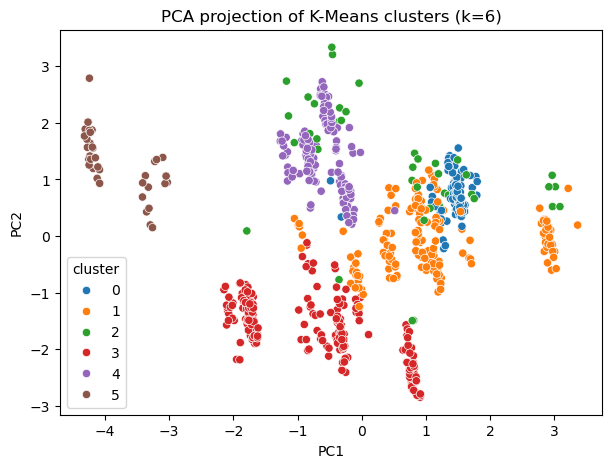

In [376]:
pca = PCA(n_components=2, random_state=42)
pca_components = pca.fit_transform(absent_scaled)

df_pca = pd.DataFrame(
    pca_components,
    columns=['PC1', 'PC2']
)
df_pca['cluster'] = cluster_labels

plt.figure(figsize=(7,5))
sns.scatterplot(
    data=df_pca,
    x='PC1',
    y='PC2',
    hue='cluster',
    palette='tab10'
)
plt.title("PCA projection of K-Means clusters (k=6)")
plt.show()


Although not perfectly separable, the PCA projection shows that clusters capture real structure in the data, validating the K-Means solution.

In [377]:
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    random_state=42
)

umap_embedding = reducer.fit_transform(absent_scaled)

C:\Users\ritam\AppData\Roaming\Python\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [378]:
df_umap = pd.DataFrame(
    umap_embedding,
    columns=['UMAP1', 'UMAP2']
)

df_umap['cluster'] = cluster_labels

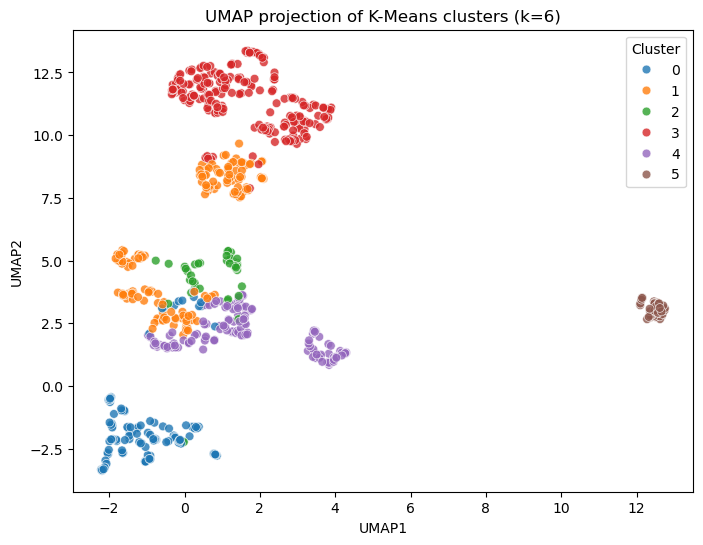

In [379]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_umap,
    x='UMAP1',
    y='UMAP2',
    hue='cluster',
    palette='tab10',
    s=40,
    alpha=0.8
)
plt.title("UMAP projection of K-Means clusters (k=6)")
plt.legend(title='Cluster')
plt.show()


UMAP confirms that the 6 clusters correspond to coherent and stable patterns, reinforcing confidence in the solution.

<font color='#006699' size=6>6. K-Prototypes Clustering </font> <a class="anchor" id="p6"></a>
  
[Back to TOC](#toc)

K-Prototypes will be tested to handle mixed data using Gower distance.

In [380]:
absent_interpret = absent_interpret.drop(columns = ["ID", "Years until retirement", "Disciplinary failure", "Education","Body mass index"])

In [381]:
absent_interpret = absent_interpret.drop(columns = ["Social smoker"])

In [382]:
df = absent_interpret.copy()

In [383]:
categorical_cols = [
    "Reason for absence",
    "Month of absence",
    "Day of the week",
    "Social drinker"
]

numerical_cols = [
    "Transportation expense",
    "Estimated commute time",
    "Service time",
    "Number of children",
    "Number of pets",
    "Absenteeism time in hours",
    "Age"
]

df_kproto = df[categorical_cols + numerical_cols].copy()

In [384]:
for col in categorical_cols:
    df_kproto[col] = df_kproto[col].astype(str)

for col in numerical_cols:
    df_kproto[col] = df_kproto[col].astype(float)


In [385]:
categorical_indices = [
    df_kproto.columns.get_loc(col)
    for col in categorical_cols
]

<h4><b>6.1 Determine the optimal K</b></h4>

In [386]:
costs = []
ks = range(2, 11)

for k in ks:
    kproto = KPrototypes(
        n_clusters=k,
        init="Cao",
        n_init=5,
        random_state=42
    )
    kproto.fit_predict(
        df_kproto.values,
        categorical=categorical_indices
    )
    costs.append(kproto.cost_)

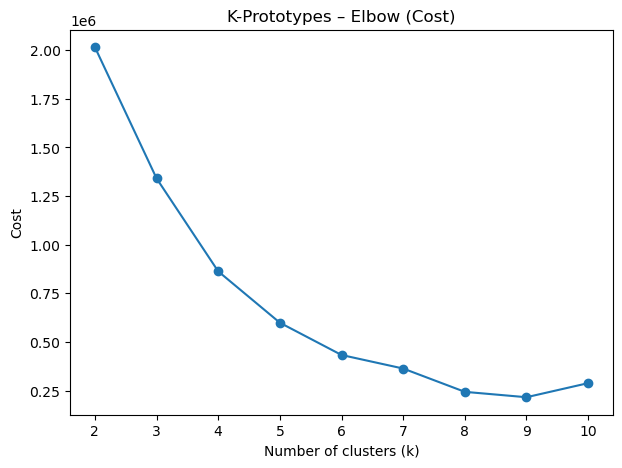

In [387]:
plt.figure(figsize=(7,5))
plt.plot(ks, costs, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Cost")
plt.title("K-Prototypes – Elbow (Cost)")
plt.show()


Unlike K-Means, K-Prototypes does not present a clear optimal k, making model selection less straightforward. Slight flattening around k=6-8

In [388]:
gower_dist = gower.gower_matrix(df_kproto)

sil_scores = []

for k in range(2, 11):
    kproto = KPrototypes(
        n_clusters=k,
        init="Cao",
        n_init=5,
        random_state=42
    )
    labels = kproto.fit_predict(
        df_kproto.values,
        categorical=categorical_indices
    )
    
    sil = silhouette_score(gower_dist, labels, metric="precomputed")
    sil_scores.append(sil)

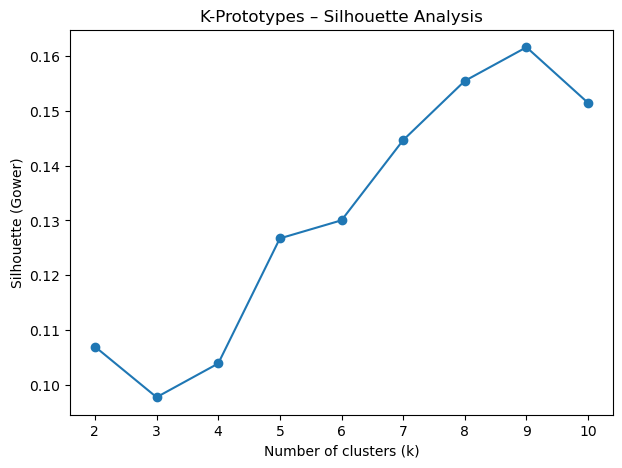

In [389]:
plt.figure(figsize=(7,5))
plt.plot(range(2,11), sil_scores, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Silhouette (Gower)")
plt.title("K-Prototypes – Silhouette Analysis")
plt.show()

The silhouette analysis using Gower distance indicates that k = 9 provides the best cluster separation for the K-Prototypes model.

After the evaluation of this two metrics, we decided to evaluate k for 7, 8 and 9 clusters.

<h4><b>6.2 Fitting Final K-Prototypes Model (k = 7,8 and 9)</b></h4>

In [390]:
ks_to_test = [7, 8, 9]

results = {}

for k in ks_to_test:
    kproto = KPrototypes(
        n_clusters=k,
        init="Cao",
        n_init=10,
        random_state=42
    )
    labels = kproto.fit_predict(
        df_kproto.values,
        categorical=categorical_indices
    )
    results[k] = labels


In [391]:
for k, labels in results.items():
    print(f"\nk = {k}")
    print(pd.Series(labels).value_counts().sort_index())


k = 7
0     64
1    122
2    216
3     91
4     70
5    113
6     94
dtype: int64

k = 8
0     37
1    113
2    222
3     33
4     56
5     94
6    122
7     93
dtype: int64

k = 9
0     56
1     33
2    126
3     81
4    122
5     92
6     37
7    130
8     93
dtype: int64


In [392]:
gower_dist = gower.gower_matrix(df_kproto)

for k, labels in results.items():
    sil = silhouette_score(gower_dist, labels, metric="precomputed")
    print(f"k = {k} | silhouette = {sil:.4f}")

k = 7 | silhouette = 0.1375
k = 8 | silhouette = 0.1554
k = 9 | silhouette = 0.1616


In [393]:
gower_dist = gower.gower_matrix(df_kproto)

In [394]:
reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    n_components=2,
    metric="precomputed",
    random_state=42
)

umap_emb = reducer.fit_transform(gower_dist)

C:\Users\ritam\AppData\Roaming\Python\Python311\site-packages\umap\umap_.py:1865: UserWarning: using precomputed metric; inverse_transform will be unavailable
  warn("using precomputed metric; inverse_transform will be unavailable")
C:\Users\ritam\AppData\Roaming\Python\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


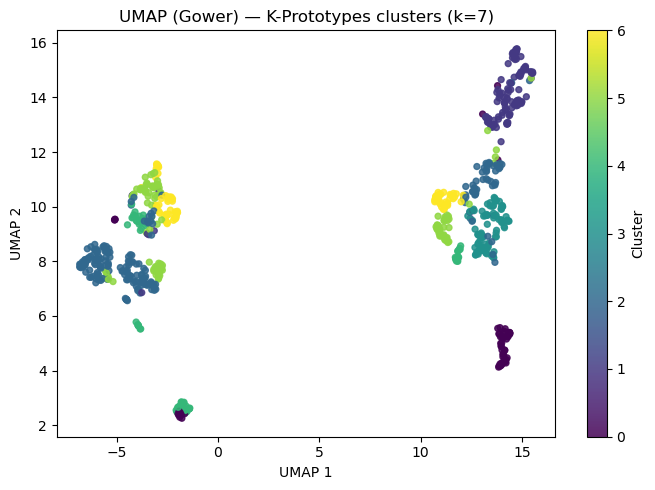

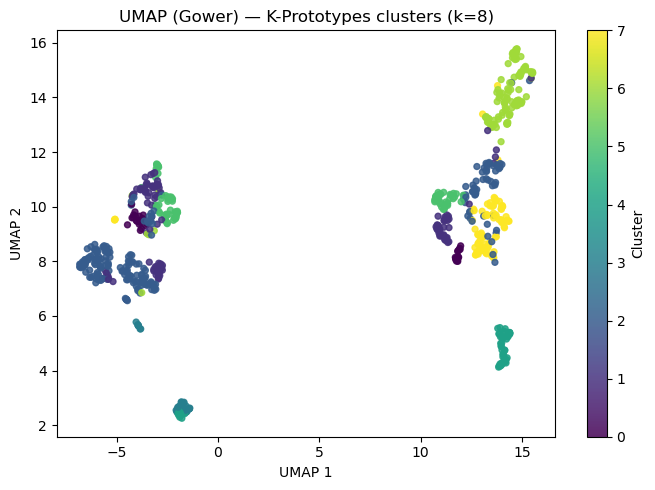

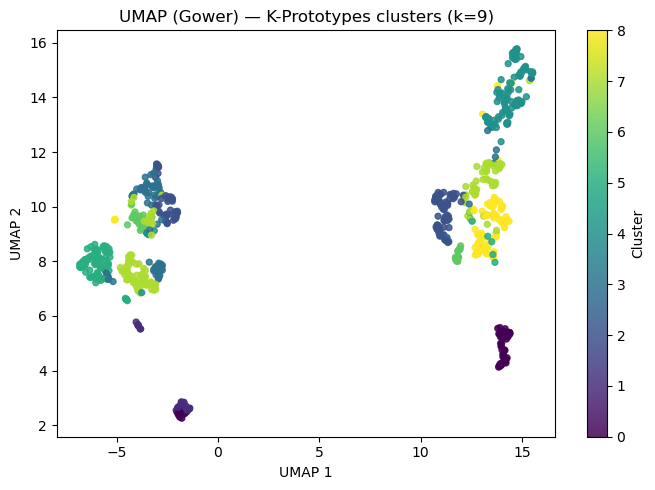

In [395]:
for k in ks_to_test:
    labels_k = results[k]

    plt.figure(figsize=(7, 5))
    sc = plt.scatter(umap_emb[:, 0], umap_emb[:, 1], c=labels_k, s=18, alpha=0.85)
    plt.title(f"UMAP (Gower) — K-Prototypes clusters (k={k})")
    plt.xlabel("UMAP 1")
    plt.ylabel("UMAP 2")
    plt.colorbar(sc, label="Cluster")
    plt.tight_layout()
    plt.show()


Both k = 8 and k = 9 produced valid clustering solutions. Although k = 9 achieved the highest silhouette score, the improvement over k = 8 was marginal. Therefore, k = 8 was selected as the final solution due to its clearer structure and greater interpretability.

<font color='#006699' size=6>7. Hierarchical Clustering (Ward)</font> <a class="anchor" id="p7"></a>
  
[Back to TOC](#toc)

In [396]:
X = absent_scaled

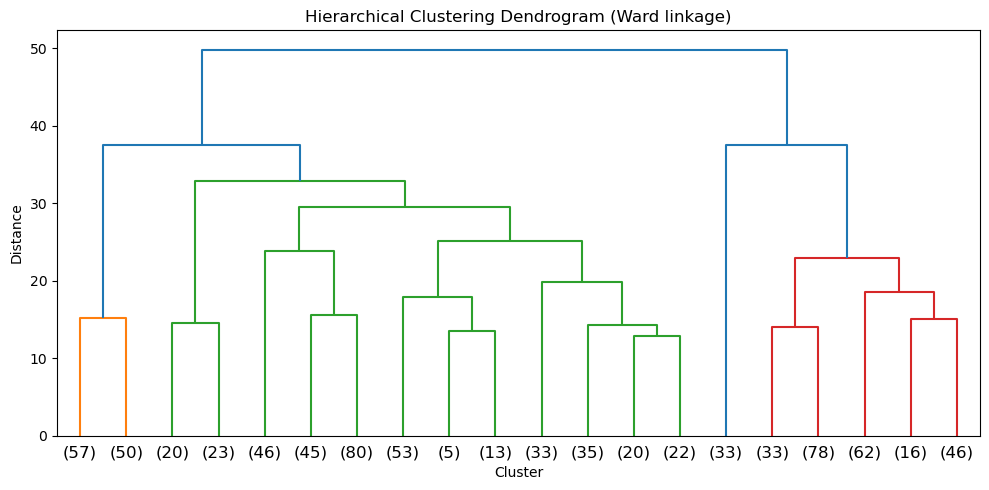

In [397]:
Z = linkage(X, method="ward")

plt.figure(figsize=(10,5))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=20
)
plt.title("Hierarchical Clustering Dendrogram (Ward linkage)")
plt.xlabel("Cluster")
plt.ylabel("Distance")
plt.tight_layout()
plt.show()


The dendrogram indicates that the dataset exhibits moderate hierarchical structure, with plausible partitions between 6 and 8 clusters.

In [398]:
ks = range(2, 11)
sil_scores = []

for k in ks:
    hc = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    labels = hc.fit_predict(X)
    sil = silhouette_score(X, labels)
    sil_scores.append(sil)

sil_df = pd.DataFrame({
    "k": ks,
    "silhouette": sil_scores
})

sil_df

,k,silhouette
0,2,0.131158
1,3,0.139503
2,4,0.140028
3,5,0.155334
4,6,0.165859
5,7,0.167993
6,8,0.167715
7,9,0.157719
8,10,0.164272


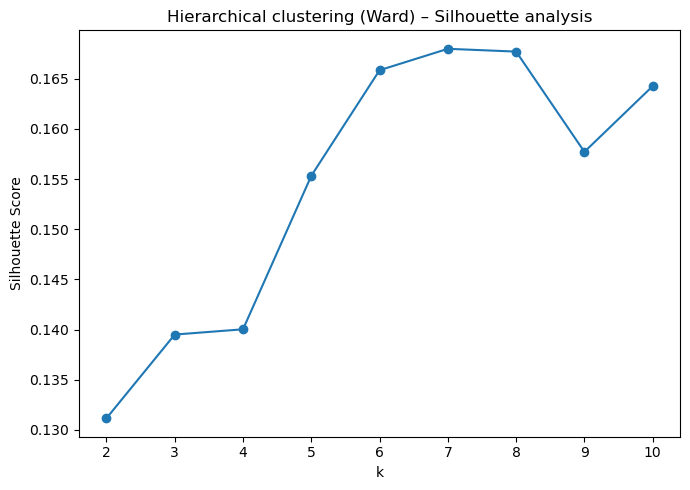

In [399]:
plt.figure(figsize=(7,5))
plt.plot(sil_df["k"], sil_df["silhouette"], marker="o")
plt.xlabel("k")
plt.ylabel("Silhouette Score")
plt.title("Hierarchical clustering (Ward) – Silhouette analysis")
plt.tight_layout()
plt.show()

Hierarchical clustering does not clearly outperform K-Means in terms of internal validation, although it confirms the presence of meaningful structure in the data.

In [400]:
X = absent_scaled
ks = [6, 7, 8]

results_hc = {}

for k in ks:
    hc = AgglomerativeClustering(
        n_clusters=k,
        linkage="ward"
    )
    labels = hc.fit_predict(X)
    results_hc[k] = labels

    print(f"\nk = {k}")
    print(pd.Series(labels).value_counts().sort_index())


k = 6
0    181
1    235
2    171
3    107
4     43
5     33
dtype: int64

k = 7
0    171
1    235
2    110
3    107
4     43
5     33
6     71
dtype: int64

k = 8
0    235
1    125
2    110
3    107
4     43
5     33
6     71
7     46
dtype: int64


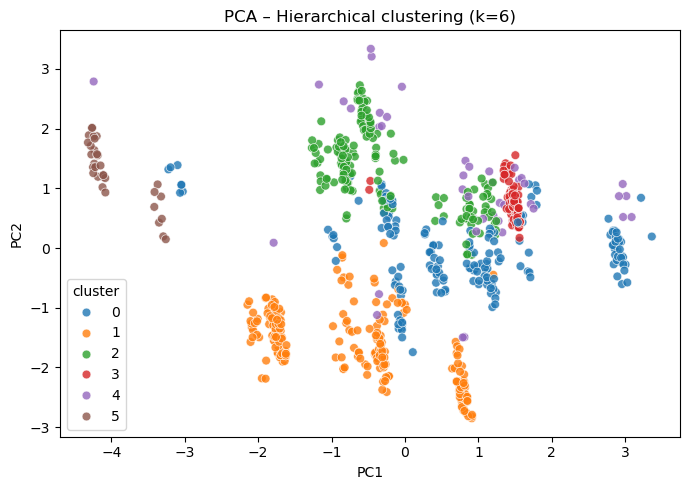

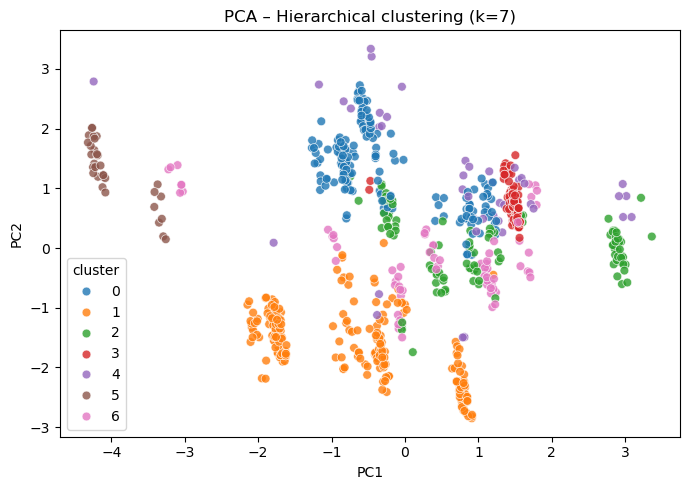

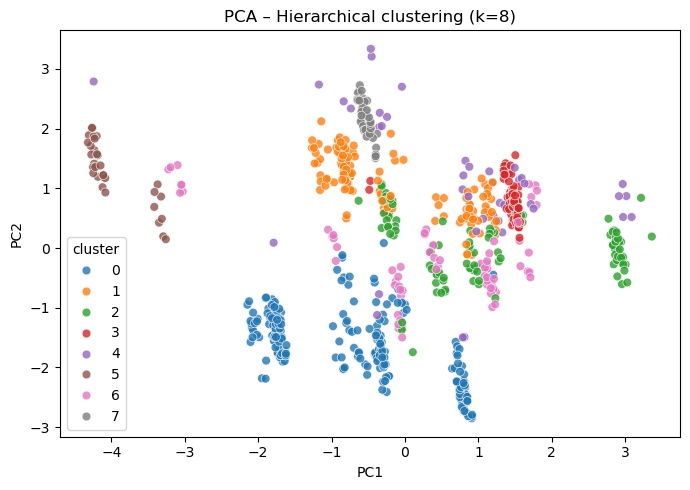

In [401]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)

df_pca = pd.DataFrame(X_pca, columns=["PC1", "PC2"])

for k, labels in results_hc.items():
    df_pca["cluster"] = labels

    plt.figure(figsize=(7,5))
    sns.scatterplot(
        data=df_pca,
        x="PC1",
        y="PC2",
        hue="cluster",
        palette="tab10",
        s=40,
        alpha=0.8
    )
    plt.title(f"PCA – Hierarchical clustering (k={k})")
    plt.tight_layout()
    plt.show()

C:\Users\ritam\AppData\Roaming\Python\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


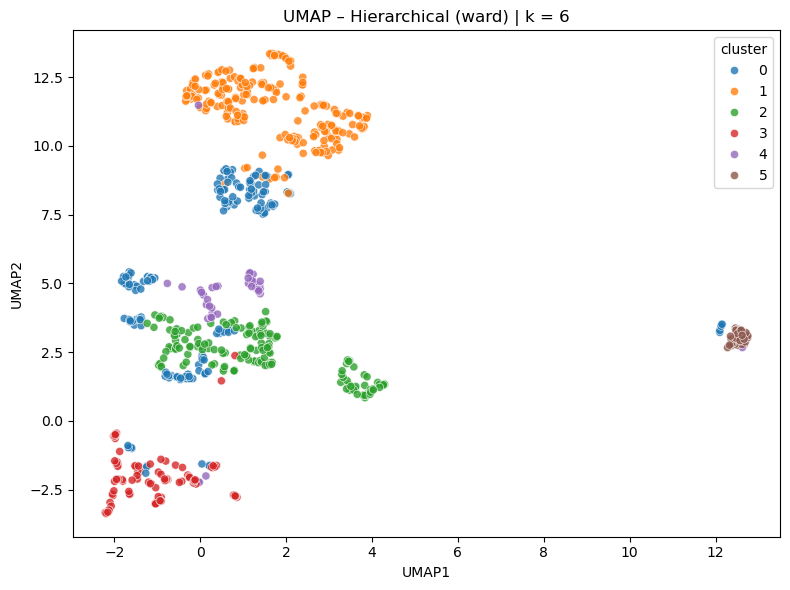

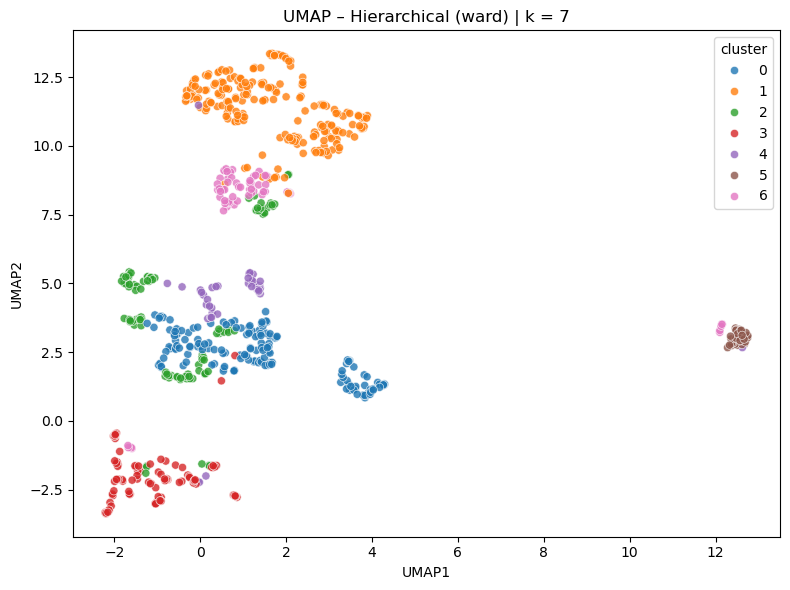

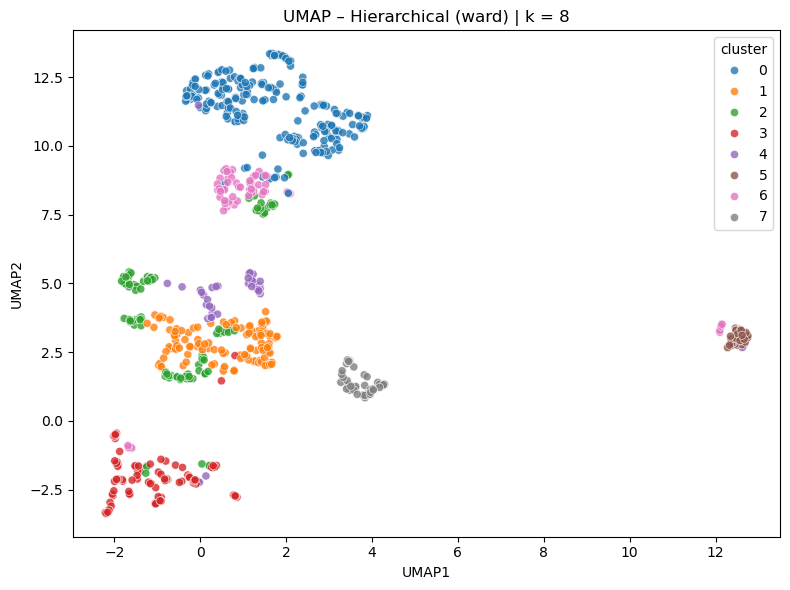

In [402]:
def plot_umaps_hierarchical_for_ks(X, ks=(6,7,8), linkage="ward",
                                  n_neighbors=15, min_dist=0.1, random_state=42):
    reducer = umap.UMAP(
        n_neighbors=n_neighbors,
        min_dist=min_dist,
        n_components=2,
        metric="euclidean",
        random_state=random_state
    )
    emb = reducer.fit_transform(X)

    df_umap = pd.DataFrame(emb, columns=["UMAP1", "UMAP2"])

    for k in ks:
        hc = AgglomerativeClustering(n_clusters=k, linkage=linkage)
        labels = hc.fit_predict(X)

        df_umap["cluster"] = labels

        plt.figure(figsize=(8,6))
        sns.scatterplot(
            data=df_umap,
            x="UMAP1",
            y="UMAP2",
            hue="cluster",
            palette="tab10",
            s=35,
            alpha=0.8
        )
        plt.title(f"UMAP – Hierarchical ({linkage}) | k = {k}")
        plt.xlabel("UMAP1")
        plt.ylabel("UMAP2")
        plt.tight_layout()
        plt.show()

plot_umaps_hierarchical_for_ks(absent_scaled, ks=[6,7,8], linkage="ward")


The solution we deciced to be the best was with k = 7, because it achieved a competitive silhouette score while maintaining clear cluster separation in the PCA and UMAP visualizations, with only marginal improvements observed for higher values of k.

<font color='#006699' size=6>8. Self-Organizing Maps (SOM)</font> <a class="anchor" id="p8"></a>
  
[Back to TOC](#toc)

In [403]:
Y = absent_scaled
n_samples, n_features = Y.shape

In [404]:
som_x, som_y = 10, 10

In [405]:
np.random.seed(42)

som = MiniSom(
    x=som_x,
    y=som_y,
    input_len=n_features,
    sigma=1.5,
    learning_rate=0.5,
    neighborhood_function="gaussian",
    random_seed=42
)

som.random_weights_init(Y)
som.train_random(Y, num_iteration=5000)

In [406]:
qe = som.quantization_error(Y)
print("Quantization Error:", qe)

Quantization Error: 1.7083941979794093


Acceptable quantization error. Indicates reasonable mapping quality

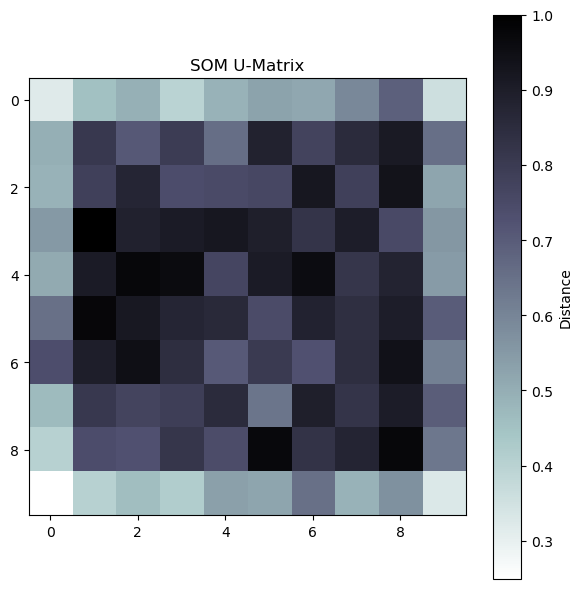

In [407]:
plt.figure(figsize=(6,6))
plt.imshow(som.distance_map().T, cmap="bone_r")
plt.colorbar(label="Distance")
plt.title("SOM U-Matrix")
plt.tight_layout()
plt.show()

Clear high-distance regions between neuron groups. Suggests underlying cluster boundaries

In [408]:
weights = som.get_weights().reshape(-1, n_features)


In [409]:
def som_cluster_metrics(som, Y, ks):
    som_x, som_y, n_feat = som.get_weights().shape
    weights = som.get_weights().reshape(-1, n_feat)

    rows = []

    for k in ks:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        neuron_labels = km.fit_predict(weights)

        
        sample_labels = []
        for x in X:
            i, j = som.winner(x)
            idx = i * som_y + j
            sample_labels.append(neuron_labels[idx])

        sample_labels = np.array(sample_labels)

        rows.append({
            "k": k,
            "silhouette": silhouette_score(X, sample_labels),
            "DBI": davies_bouldin_score(X, sample_labels),
            "min_cluster_size": pd.Series(sample_labels).value_counts().min(),
            "max_cluster_size": pd.Series(sample_labels).value_counts().max()
        })

    return pd.DataFrame(rows)

In [410]:
ks = [3, 4, 5, 6, 7, 8, 9, 10]
som_metrics = som_cluster_metrics(som, Y, ks)
som_metrics


c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than availabl

,k,silhouette,DBI,min_cluster_size,max_cluster_size
0,3,0.123939,2.513486,220,298
1,4,0.151786,2.157426,128,234
2,5,0.167310,2.079641,41,234
3,6,0.179000,1.876935,41,229
4,7,0.153478,2.024417,37,173
5,8,0.149512,2.108680,37,148
6,9,0.166070,1.971743,37,124
7,10,0.165471,1.994822,36,123


The solution with k = 6 provided a favorable trade-off, achieving a relatively low DBI, the higher silhouette performance. For these reasons, k = 6 was selected as the final clustering solution for the SOM-based analysis.

In [411]:
k_final = 6 

weights = som.get_weights().reshape(-1, n_features)
km = KMeans(n_clusters=k_final, random_state=42, n_init=10)
neuron_labels = km.fit_predict(weights)

labels_final = []
for x in X:
    i, j = som.winner(x)
    labels_final.append(neuron_labels[i * som_y + j])

labels_final = np.array(labels_final)


c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


In [412]:
cluster_counts = pd.Series(labels_final, name="cluster").value_counts().sort_index()
print(cluster_counts)

0    132
1    229
2    134
3    190
4     41
5     44
Name: cluster, dtype: int64


C:\Users\ritam\AppData\Roaming\Python\Python311\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


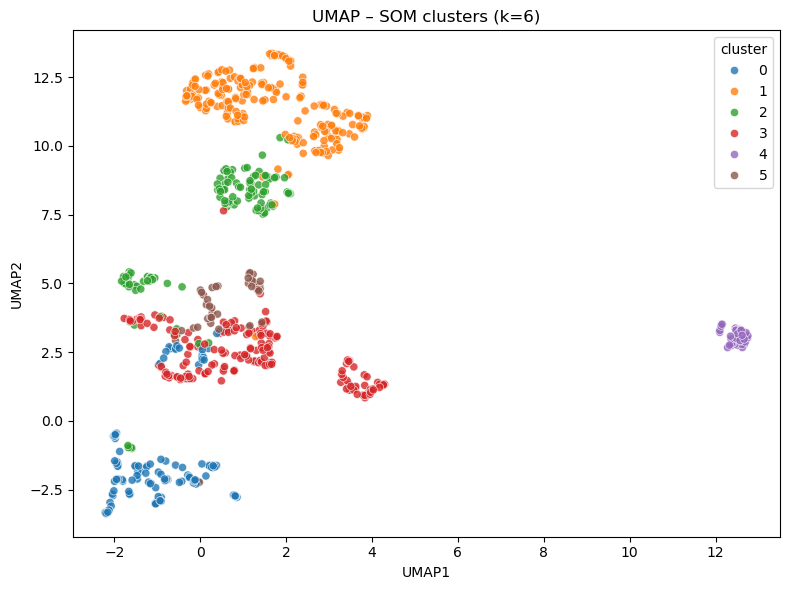

In [413]:
emb = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    random_state=42
).fit_transform(X)

df_umap = pd.DataFrame(emb, columns=["UMAP1", "UMAP2"])
df_umap["cluster"] = labels_final

plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df_umap,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette="tab10",
    s=35,
    alpha=0.8
)
plt.title(f"UMAP – SOM clusters (k={k_final})")
plt.tight_layout()
plt.show()

<font color='#006699' size=6>9. Final Model Selection and Export</font> <a class="anchor" id="p9"></a>
  
[Back to TOC](#toc)

In [414]:
K_KMEANS = 6
K_KPROTO = 8
K_SOM    = 6
K_HIER   = 7

rows = []

def add_row(name, labels, X_for_metrics=None, silhouette_precomputed=None, dbi_ok=True):
    labels = np.asarray(labels)
    counts = pd.Series(labels).value_counts()
    if silhouette_precomputed is not None:
        sil = silhouette_score(silhouette_precomputed, labels, metric="precomputed")
    else:
        sil = silhouette_score(X_for_metrics, labels)
    dbi = np.nan
    if dbi_ok and X_for_metrics is not None:
        dbi = davies_bouldin_score(X_for_metrics, labels)

    rows.append({
        "Algorithm": name,
        "k": len(np.unique(labels)),
        "Silhouette": float(sil),
        "DBI": (float(dbi) if np.isfinite(dbi) else np.nan),
        "Min cluster size": int(counts.min()),
        "Max cluster size": int(counts.max())
    })

kmeans = KMeans(n_clusters=K_KMEANS, random_state=42, n_init=10)
labels_kmeans = kmeans.fit_predict(absent_scaled)
add_row("K-Means", labels_kmeans, X_for_metrics=absent_scaled, dbi_ok=True)

kproto = KPrototypes(n_clusters=K_KPROTO, init="Cao", n_init=5, random_state=42)
labels_kproto = kproto.fit_predict(df_kproto.values, categorical=categorical_indices)
add_row("K-Prototypes", labels_kproto, silhouette_precomputed=gower_dist, dbi_ok=False)

labels_som = labels_final
add_row("SOM", labels_som, X_for_metrics=absent_scaled, dbi_ok=True)

hc = AgglomerativeClustering(n_clusters=K_HIER, linkage="ward")
labels_hier = hc.fit_predict(absent_scaled)
add_row("Hierarchical (Ward)", labels_hier, X_for_metrics=absent_scaled, dbi_ok=True)

df_compare = pd.DataFrame(rows).sort_values(by="Silhouette", ascending=False)
df_compare


c:\Anaconda\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=4.
  warnings.warn(


,Algorithm,k,Silhouette,DBI,Min cluster size,Max cluster size
0,K-Means,6,0.185580,1.866961,41,235
2,SOM,6,0.179000,1.876935,41,229
3,Hierarchical (Ward),7,0.167993,1.905654,33,235
1,K-Prototypes,8,0.155436,NaN,33,222


After testing multiple clustering approaches (K-Means, K-Prototypes, Hierarchical Clustering, and SOM), K-Means with k = 6 was selected as the final solution.
<br>
This choice is supported by:
- The highest silhouette score
- The lowest Davies–Bouldin Index
- Balanced cluster sizes
- Strong visual separation in PCA and UMAP
- Superior interpretability compared to mixed-data methods<br>

In [415]:
df_clusters.to_csv("kmeans_k6_clusters_for_analysis.csv", index=False)

In [416]:
df_raw = absent_for_clustering.copy()
df_raw["cluster"] = cluster_labels

df_raw.to_csv("kmeans_k6_raw_with_cluster.csv", index=False)

In [417]:
df_scaled = pd.DataFrame(
    absent_scaled,
    columns=absent_for_clustering.columns
)
df_scaled["cluster"] = cluster_labels

df_scaled.to_csv("kmeans_k6_scaled_with_cluster.csv", index=False)
